In [1]:
pip install numpy matplotlib

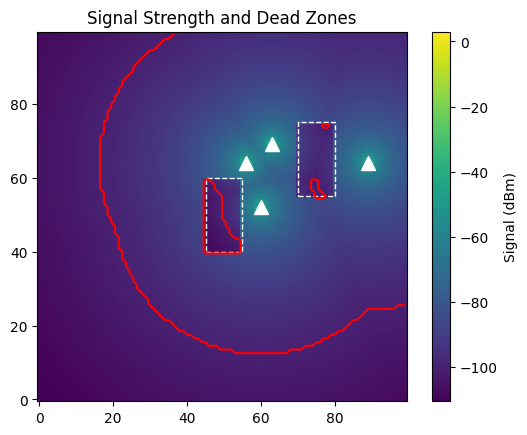

Dead zone area: 38.4%


In [3]:
import numpy as np
import matplotlib.pyplot as plt

size = 100
cell_m = 22
x, y = np.meshgrid(np.arange(size), np.arange(size))

towers = [(60, 52), (63, 69), (56, 64), (89, 64)]

tx_power = 43
pl0 = 40
n = 3.5
threshold = -100

# Obstacles: (x_start, x_end, y_start, y_end, extra_loss_dB)
obstacles = [
    (45, 55, 40, 60, 20),
    (70, 80, 55, 75, 15),
]

loss = np.zeros((size, size))
for x1, x2, y1, y2, db in obstacles:
    loss[y1:y2, x1:x2] = db

best = np.full((size, size), -np.inf)
for tx, ty in towers:
    d = np.sqrt((x - tx)**2 + (y - ty)**2) * cell_m + 1
    signal = tx_power - pl0 - 10 * n * np.log10(d) - loss
    best = np.maximum(best, signal)

dead = best < threshold

plt.imshow(best, cmap="viridis", origin="lower")
plt.colorbar(label="Signal (dBm)")
plt.contour(dead, levels=[0.5], colors="red")
for tx, ty in towers:
    plt.plot(tx, ty, "w^", markersize=10)
for x1, x2, y1, y2, db in obstacles:
    plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                        fill=False, edgecolor="white", linestyle="--"))
plt.title("Signal Strength and Dead Zones")
plt.savefig("with_obstacles.png", dpi=150)
plt.show()

print("Dead zone area: %.1f%%" % (dead.mean() * 100))

A: Original 4 towers -> dead zone 38.4%


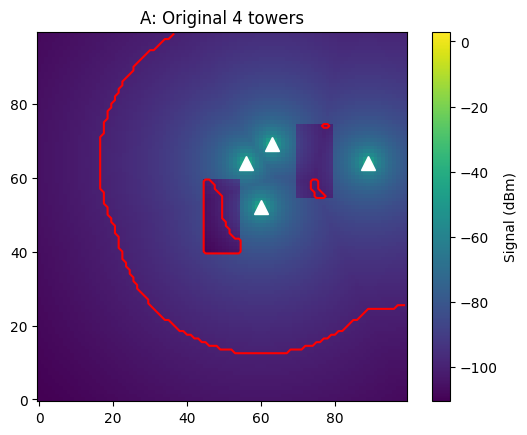

B: Add 1 tower on left -> dead zone 20.3%


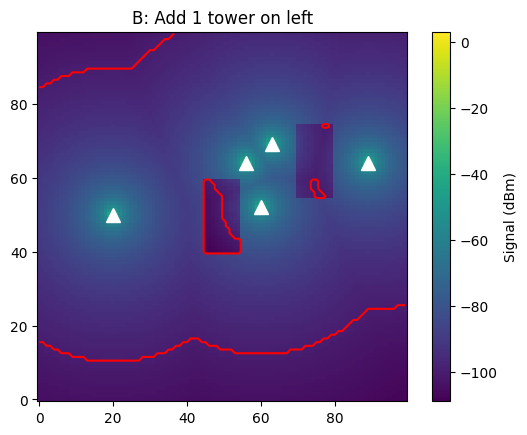

C: Add 2 towers (left + bottom) -> dead zone 9.1%


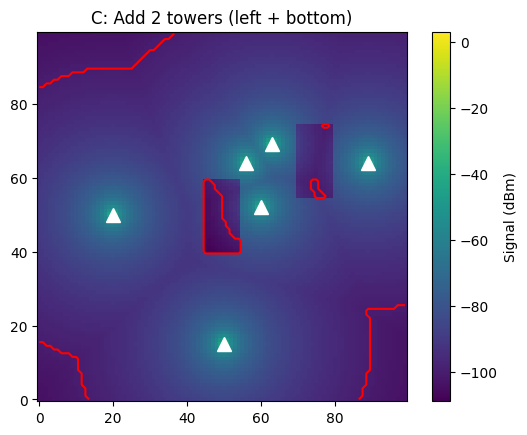

D: Add 1 tower near existing -> dead zone 38.3%


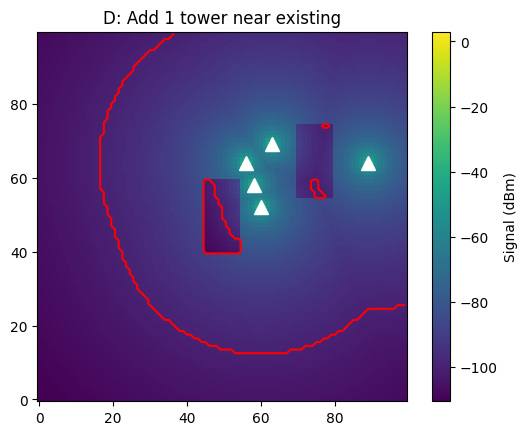

In [4]:
def run(towers, n=3.5, threshold=-100, tx_power=43):
    best = np.full((size, size), -np.inf)
    for tx, ty in towers:
        d = np.sqrt((x - tx)**2 + (y - ty)**2) * cell_m + 1
        signal = tx_power - pl0 - 10 * n * np.log10(d) - loss
        best = np.maximum(best, signal)
    dead = best < threshold
    return best, dead

base = [(60, 52), (63, 69), (56, 64), (89, 64)]

experiments = {
    "A: Original 4 towers": base,
    "B: Add 1 tower on left": base + [(20, 50)],
    "C: Add 2 towers (left + bottom)": base + [(20, 50), (50, 15)],
    "D: Add 1 tower near existing": base + [(58, 58)],
}

for name, t in experiments.items():
    best, dead = run(t)
    print("%s -> dead zone %.1f%%" % (name, dead.mean() * 100))
    plt.figure()
    plt.imshow(best, cmap="viridis", origin="lower")
    plt.colorbar(label="Signal (dBm)")
    plt.contour(dead, levels=[0.5], colors="red")
    for tx, ty in t:
        plt.plot(tx, ty, "w^", markersize=10)
    plt.title(name)
    plt.savefig(name[0] + ".png", dpi=150)
    plt.show()